# AJA · Quanto tempo a Prefeitura leva para responder a uma barreira na calçada?

**Equipe:** Guilherme Santos Nunes (RM558989) · Kaique Rodrigues Zaffarani (RM556677) · Pedro Josué Pereira Almeida (RM554913)

**Global Solution 2026.2 · CitizenTech · Inteligência Artificial & Machine Learning**

O AJA é uma plataforma de participação cidadã para pessoas com deficiência visual e auditiva do
Parque Doroteia (Subprefeitura Cidade Ademar, São Paulo). Quem relata uma barreira (calçada quebrada,
obstáculo, travessia insegura, semáforo de pedestre com tempo curto) precisa saber o que esperar
depois de abrir o pedido na Prefeitura.

**Pergunta de ML:** no momento em que um pedido sobre barreira para pedestres é aberto no SP156,
ele será **finalizado em até 30 dias**?

- Tipo de problema: classificação binária supervisionada (o modelo aprende com exemplos já rotulados e
  responde “sim” ou “não”).
- Alvo `y = 1`: pedido finalizado em até 30 dias após a abertura.
- Alvo `y = 0`: finalizado depois de 30 dias **ou** ainda aberto mais de 30 dias após a abertura.
- Modelo: **XGBoost**, comparado com um baseline simples.

Roteiro:
1. Dados reais e públicos (fonte, link e período)
2. Limpeza e construção do alvo
3. Exploração
4. Divisão treino/teste
5. Treino com diferentes hiperparâmetros (validação cruzada só no treino)
6. Resultados em treino e teste, overfitting
7. Leitura para o cidadão
8. Conclusões

### Glossário rápido

| Termo | Em palavras simples |
|---|---|
| Treino / teste | O modelo aprende com o conjunto de treino e é avaliado no de teste, que ele nunca viu. |
| Baseline | Regra simples usada como régua: o modelo só vale a pena se for melhor que ela. |
| Hiperparâmetro | Configuração escolhida antes do treino, como a profundidade das árvores. |
| Validação cruzada | Divide o treino em partes e testa cada configuração várias vezes, para escolher sem tocar no teste. |
| Overfitting | O modelo decora o treino em vez de aprender o padrão, e erra mais em dados novos. |
| Boosting | Várias árvores de decisão pequenas em sequência; cada uma corrige os erros das anteriores. |
| One-hot encoding | Transforma uma categoria (ex.: subprefeitura) em colunas de 0 e 1 que o modelo consegue ler. |
| Censura | Pedido cujo desfecho ainda não aconteceu na data da extração, então o rótulo é desconhecido. |
| Vazamento | Usar uma informação que só existe depois do fato que queremos prever. Deixa o modelo artificialmente bom. |

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from xgboost import XGBClassifier

SEED = 42
FIG = Path("figuras")
FIG.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 80)

## 1. Dados reais e públicos

| Item | Valor |
|---|---|
| Fonte | Portal de Dados Abertos da Prefeitura de São Paulo, conjunto **Dados do SP156 – Solicitações** |
| Link | http://dados.prefeitura.sp.gov.br/dataset/dados-do-sp156 |
| Período | pedidos abertos de **jan/2020 a set/2026** (arquivos trimestrais) |
| Extração | arquivos baixados em 13/11/2026; status e datas de finalização refletem a data de extração de cada arquivo pela Prefeitura (jul. a out. de 2026; um arquivo em nov. de 2025) |
| Recorte | 10 serviços ligados a barreiras no caminho do pedestre (lista abaixo) |
| Arquivo | `dados/sp156_barreiras_pedestre_2020_2026.csv.gz` |

Cada arquivo trimestral tem de 300 mil a 1,1 milhão de pedidos de todos os temas. O script
`dados/extrair_sp156.py` baixa os CSVs, identifica as colunas pelo nome (a ordem, o separador e a
codificação mudam entre trimestres) e mantém só os serviços abaixo. Detalhes e limitações em
`dados/README.md`.

**Privacidade:** a base pública não traz nome nem documento de quem abriu o pedido. Mesmo assim,
removemos logradouro, número e CEP e arredondamos latitude/longitude para 3 casas (cerca de 100 m).

In [2]:
df = pd.read_csv(
    "dados/sp156_barreiras_pedestre_2020_2026.csv.gz",
    parse_dates=["data_abertura", "data_finalizacao", "data_extracao_arquivo"],
)
print(f"{len(df):,} pedidos | abertura de {df.data_abertura.min():%d/%m/%Y} a {df.data_abertura.max():%d/%m/%Y}")
df.head()

120,248 pedidos | abertura de 01/01/2020 a 30/09/2026


,data_abertura,data_finalizacao,data_extracao_arquivo,canal,tema,assunto,servico,status,orgao,lat_aprox,lon_aprox,subprefeitura,distrito,arquivo_origem
0,2020-01-01,NaT,2026-08-03,CRM,Rua e bairro,"Calçadas, guias e postes",Acessibilidade - solicitar avaliação de obstáculo na calçada,Aberto,INTEGRACAO-SGF,-23.726,-46.687,CAPELA DO SOCORRO,CIDADE DUTRA,1-trimestre-2020.csv
1,2020-01-01,2020-03-04,2026-08-03,CRM,Rua e bairro,"Calçadas, guias e postes",Calçada particular - denunciar calçada danificada ou inexistente,Finalizada,INTEGRACAO-SGF,-23.553,-46.654,SE,CONSOLACAO,1-trimestre-2020.csv
2,2020-01-01,2021-05-31,2026-08-03,PORTAL,Rua e bairro,"Calçadas, guias e postes",Calçada particular - denunciar calçada danificada ou inexistente,Finalizada,INTEGRACAO-SGF,-23.584,-46.670,PINHEIROS,MOEMA,1-trimestre-2020.csv
3,2020-01-01,2020-05-08,2026-08-03,PORTAL,Rua e bairro,"Calçadas, guias e postes",Calçada pública - solicitar manutenção,Finalizada,INTEGRAÇÃO-SMGI/SGZ,-23.591,-46.507,SAPOPEMBA,SAPOPEMBA,1-trimestre-2020.csv
4,2020-01-01,2020-01-01,2026-08-03,PORTAL,Rua e bairro,"Calçadas, guias e postes",Sugerir construção de calçadas em áreas públicas e praças,Finalizada,SMPR-CPO-STM-Sugestão,-23.584,-46.503,SAO MATEUS,SAO MATEUS,1-trimestre-2020.csv


In [3]:
df.servico.value_counts().to_frame("pedidos")

,pedidos
servico,
Calçada pública - solicitar manutenção,26470
Acessibilidade - solicitar avaliação de obstáculo na calçada,24751
Calçada particular - denunciar calçada danificada ou inexistente,19995
Sinalização horizontal apagada (pintura de solo) – Solicitar repintura,17821
Semáforo de veículos e pedestres - Sugerir ajuste de tempo,12804
Travessia de pedestres - Solicitar avaliação,9372
Sugerir construção de calçadas em áreas públicas e praças,3532
Guias para travessia de pedestres - Solicitar rebaixamento,3440
Guia rebaixada - solicitar fiscalização de rebaixamento irregular,2044


## 2. Limpeza e construção do alvo

1. **Padronizar subprefeitura.** O nome muda entre anos (ex.: `M'BOI MIRIM`, `M´BOI MIRIM`, `M BOI MIRIM`).
   Valores que não são subprefeituras (ex.: “Superintendência das Usinas de Asfalto”) ou vazios são
   preenchidos a partir do distrito.
2. **Remover serviços sem tempo de atendimento real:** “Sugerir construção de calçadas” é fechado
   no mesmo dia (é uma sugestão registrada, não um atendimento) e “Manutenção de semáforos” tem só 19 casos.
3. **Remover pedidos cancelados pelo próprio cidadão:** não houve resposta do órgão.
4. **Censura:** um pedido aberto há menos de 30 dias na data de extração ainda pode ser finalizado
   dentro do prazo. Não sabemos o rótulo dele, então sai da base.
5. **Sem vazamento:** usamos apenas o que se sabe no momento da abertura. Data de finalização e status
   não entram como variáveis. O campo `orgao` também fica de fora porque, segundo o dicionário de dados,
   mostra o órgão no dia da extração (pedidos podem ser transferidos depois de abertos).

In [4]:
# 1. Padronizar subprefeitura
ajustes = {
    "M'BOI MIRIM": "M BOI MIRIM",
    "M´BOI MIRIM": "M BOI MIRIM",
    "CASA VERDE-LIMAO-CACHOEIRINHA": "CASA VERDE-CACHOEIRINHA",
    "PERUS-ANHANGUERA": "PERUS",
}
df["subprefeitura"] = df.subprefeitura.replace(ajustes)
contagem = df.subprefeitura.value_counts()
subprefeituras_validas = set(contagem[contagem > 500].index)
df.loc[~df.subprefeitura.isin(subprefeituras_validas), "subprefeitura"] = np.nan
sub_por_distrito = (
    df.dropna(subset=["subprefeitura", "distrito"])
    .groupby("distrito").subprefeitura.agg(lambda s: s.mode()[0])
)
df["subprefeitura"] = df.subprefeitura.fillna(df.distrito.map(sub_por_distrito)).fillna("NAO INFORMADA")
print("subprefeituras:", df.subprefeitura.nunique(), "(32 oficiais + NAO INFORMADA)")

# 2 e 3. Serviços sem tempo real e pedidos cancelados
df = df[~df.servico.str.startswith(("Sugerir construção", "Manutenção de semáforos"))]
df = df[df.status != "Cancelada"].copy()

# 4. Alvo com tratamento de censura
df["dias_ate_finalizar"] = (df.data_finalizacao - df.data_abertura).dt.days
idade_na_extracao = (df.data_extracao_arquivo - df.data_abertura).dt.days
finalizado = df.status == "Finalizada"
df["y"] = np.select(
    [finalizado & (df.dias_ate_finalizar <= 30), finalizado | (idade_na_extracao > 30)],
    [1, 0],
    default=-1,  # rótulo desconhecido
)
print("pedidos com rótulo desconhecido (removidos):", (df.y == -1).sum())
df = df[df.y >= 0].copy()
print(f"base final: {len(df):,} pedidos | {df.y.mean():.1%} finalizados em até 30 dias")

subprefeituras: 33 (32 oficiais + NAO INFORMADA)
pedidos com rótulo desconhecido (removidos): 888
base final: 115,133 pedidos | 42.5% finalizados em até 30 dias


### Variáveis (features)

| Variável | Origem | Por quê |
|---|---|---|
| `servico` | SP156 | tipo de barreira; cada serviço tem órgão e rito próprios |
| `canal` | SP156 | portal, telefone 156, aplicativo ou chatbot |
| `subprefeitura` | SP156 | capacidade de atendimento varia por região |
| `lat_aprox`, `lon_aprox` | SP156 (arredondadas) | localização fina, sem identificar o endereço |
| `mes`, `dia_semana` | data de abertura | sazonalidade (chuvas, fim de ano) |
| `carga_30d` | calculada | pedidos do mesmo serviço na mesma subprefeitura nos 30 dias **anteriores** (tamanho da fila) |

In [5]:
df = df.sort_values("data_abertura").reset_index(drop=True)
df["mes"] = df.data_abertura.dt.month
df["dia_semana"] = df.data_abertura.dt.dayofweek

# carga_30d: só olha para trás (closed="left" exclui o próprio dia)
diario = df.groupby(["servico", "subprefeitura", "data_abertura"]).size().rename("n").reset_index()
diario["carga_30d"] = (
    diario.groupby(["servico", "subprefeitura"], group_keys=False)
    .apply(lambda g: g.set_index("data_abertura").n.rolling("30D", closed="left").sum())
    .values
)
df = df.merge(diario[["servico", "subprefeitura", "data_abertura", "carga_30d"]], how="left")
df["carga_30d"] = df.carga_30d.fillna(0)

CATEGORICAS = ["servico", "canal", "subprefeitura"]
NUMERICAS = ["lat_aprox", "lon_aprox", "mes", "dia_semana", "carga_30d"]
NOME_CURTO = {
    "Acessibilidade - solicitar avaliação de obstáculo na calçada": "Obstáculo na calçada (acessibilidade)",
    "Calçada particular - denunciar calçada danificada ou inexistente": "Calçada particular danificada",
    "Calçada pública - solicitar manutenção": "Manutenção de calçada pública",
    "Sinalização horizontal apagada (pintura de solo) – Solicitar repintura": "Faixa/pintura de solo apagada",
    "Semáforo de veículos e pedestres - Sugerir ajuste de tempo": "Ajuste de tempo de semáforo",
    "Travessia de pedestres - Solicitar avaliação": "Avaliação de travessia",
    "Guias para travessia de pedestres - Solicitar rebaixamento": "Rebaixamento de guia p/ travessia",
    "Guia rebaixada - solicitar fiscalização de rebaixamento irregular": "Guia rebaixada irregular",
}
X = pd.get_dummies(df[CATEGORICAS + NUMERICAS], columns=CATEGORICAS, dtype=float)
y = df.y
print("matriz X:", X.shape, "(linhas = pedidos, colunas = variáveis depois do one-hot)")

matriz X: (115133, 51) (linhas = pedidos, colunas = variáveis depois do one-hot)


## 3. Exploração

In [6]:
fin = df[df.status == "Finalizada"]
resumo = (
    fin.groupby("servico").dias_ate_finalizar
    .agg(pedidos="count", mediana_dias="median", p75_dias=lambda s: s.quantile(.75))
    .join(df.groupby("servico").y.mean().rename("taxa_ate_30d"))
    .sort_values("mediana_dias")
)
resumo.index = resumo.index.map(NOME_CURTO)
resumo.style.format({"taxa_ate_30d": "{:.0%}", "p75_dias": "{:.0f}", "mediana_dias": "{:.0f}"})

,pedidos,mediana_dias,p75_dias,taxa_ate_30d
servico,,,,
Rebaixamento de guia p/ travessia,3298,4,21,77%
Ajuste de tempo de semáforo,12628,10,22,82%
Manutenção de calçada pública,23893,12,48,61%
Faixa/pintura de solo apagada,17056,16,50,62%
Avaliação de travessia,8887,17,51,61%
Guia rebaixada irregular,695,157,404,5%
Calçada particular danificada,10150,234,640,7%
Obstáculo na calçada (acessibilidade),11780,266,685,7%


**Como ler:** `mediana_dias` é o tempo do pedido “do meio” (metade foi mais rápida, metade mais lenta);
`p75_dias` é o tempo em que 75% dos pedidos já tinham sido finalizados; `taxa_ate_30d` é a fração
finalizada em até 30 dias.

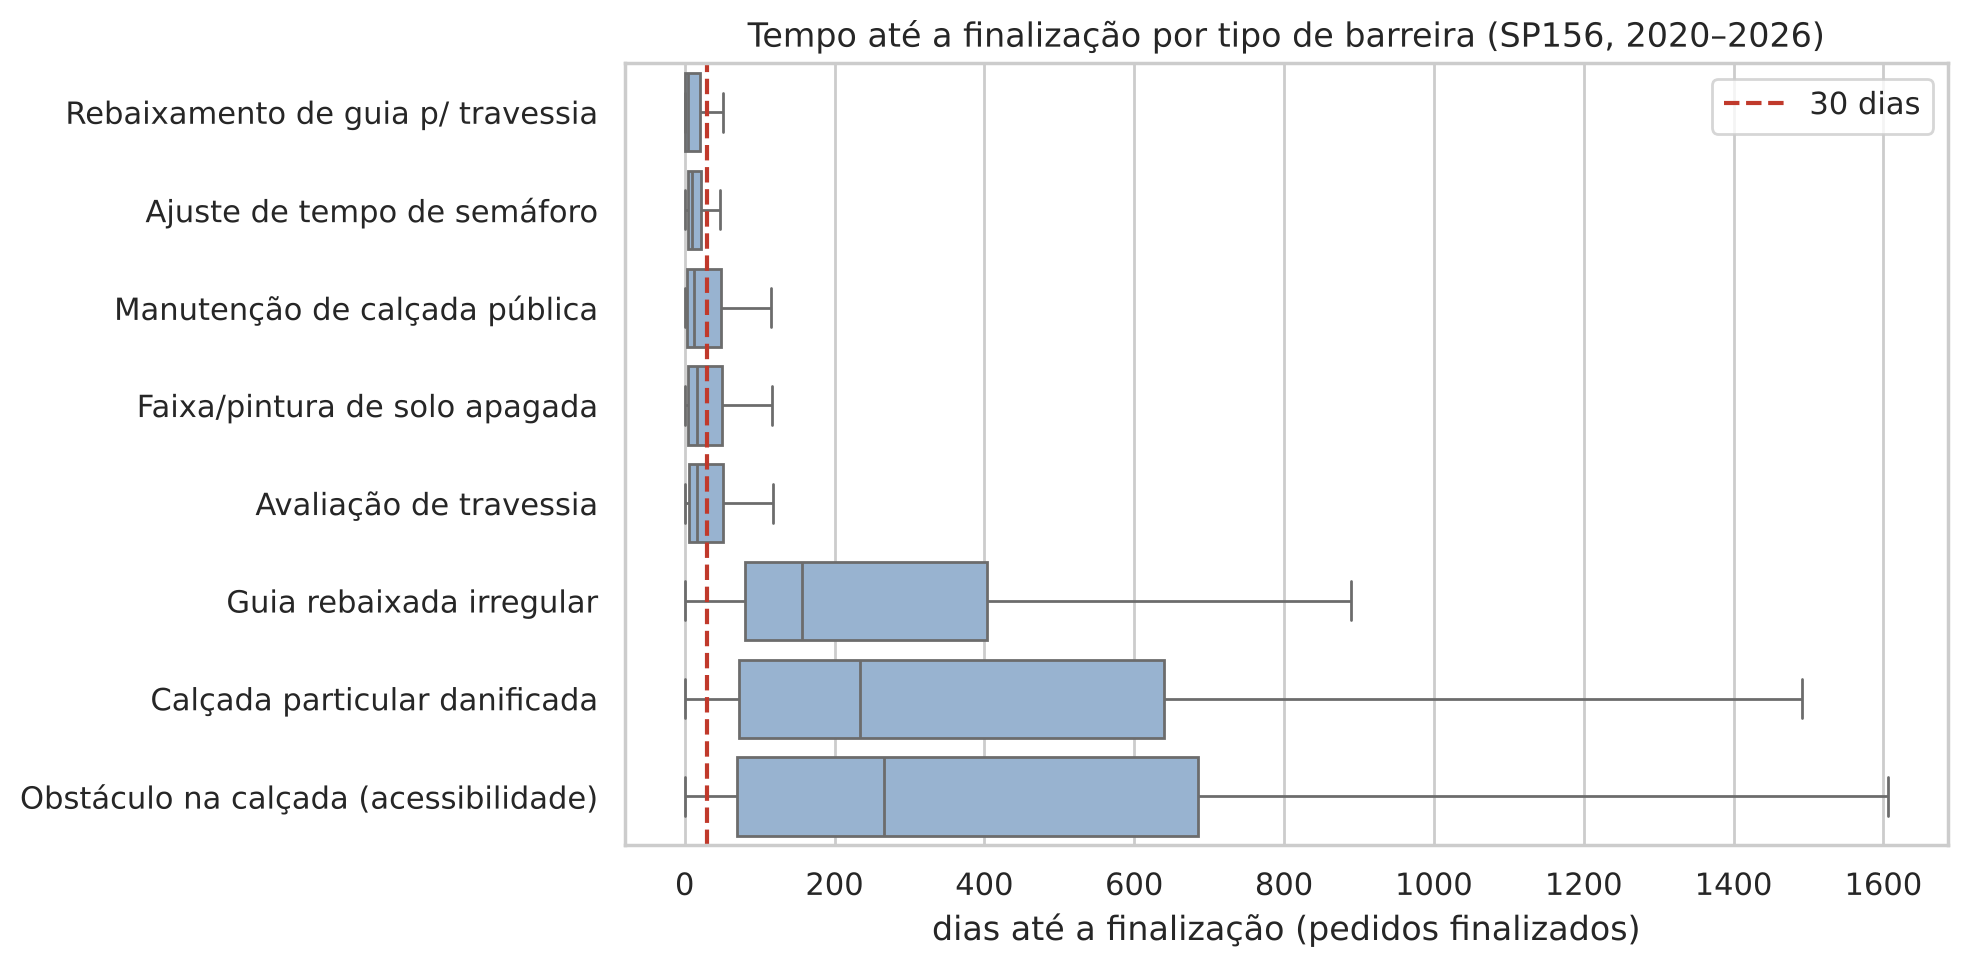

In [7]:
ordem = resumo.index
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=fin.assign(servico=fin.servico.map(NOME_CURTO)), y="servico", x="dias_ate_finalizar",
            order=ordem, showfliers=False, ax=ax, color="#8fb3d9")
ax.axvline(30, color="#c0392b", ls="--", label="30 dias")
ax.set(xlabel="dias até a finalização (pedidos finalizados)", ylabel="",
       title="Tempo até a finalização por tipo de barreira (SP156, 2020–2026)")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "01_dias_por_servico.png", dpi=130); plt.show()

**Como ler o gráfico:** cada caixa vai do pedido mais rápido de 25% ao de 75%; a linha dentro dela é a
mediana; as hastes mostram a faixa típica, sem os casos extremos. A linha vermelha marca 30 dias.

**O que mostra:** há dois grupos bem separados.
- **Rápidos:** ajuste de semáforo, rebaixamento de guia, manutenção de calçada pública, faixa apagada e
  avaliação de travessia ficam quase todos perto ou abaixo de 30 dias.
- **Lentos:** guia rebaixada irregular, calçada particular danificada e **obstáculo na calçada** têm
  medianas de meses e caixas que passam de um ano e meio.

O tipo de serviço, sozinho, já separa bem os pedidos rápidos dos lentos.

In [8]:
LENTOS = ("Acessibilidade", "Calçada particular", "Guia rebaixada")
df["grupo"] = np.where(df.servico.str.startswith(LENTOS), "lentos", "rápidos")
ano = df.data_abertura.dt.year
por_ano = pd.DataFrame({
    "pedidos": df.groupby(ano).size(),
    "trimestres_na_base": df.groupby(ano).arquivo_origem.nunique(),
    "taxa_geral": df.groupby(ano).y.mean(),
    "taxa_rapidos": df[df.grupo == "rápidos"].groupby(ano[df.grupo == "rápidos"]).y.mean(),
    "taxa_lentos": df[df.grupo == "lentos"].groupby(ano[df.grupo == "lentos"]).y.mean(),
    "parcela_lentos": (df.grupo == "lentos").groupby(ano).mean(),
})
por_ano["pedidos_por_trimestre"] = por_ano.pedidos / por_ano.trimestres_na_base
por_ano.style.format({c: "{:.0%}" for c in ["taxa_geral", "taxa_rapidos", "taxa_lentos", "parcela_lentos"]} | {"pedidos_por_trimestre": "{:,.0f}"})

,pedidos,trimestres_na_base,taxa_geral,taxa_rapidos,taxa_lentos,parcela_lentos,pedidos_por_trimestre
data_abertura,,,,,,,
2020,11541,4,33%,60%,5%,48%,"2,885"
2021,7666,3,43%,73%,5%,45%,"2,555"
2022,15006,4,44%,69%,6%,40%,"3,752"
2023,20352,4,44%,68%,6%,39%,"5,088"
2024,17229,3,45%,66%,9%,37%,"5,743"
2025,23960,4,46%,66%,10%,36%,"5,990"
2026,19379,3,39%,61%,6%,40%,"6,460"


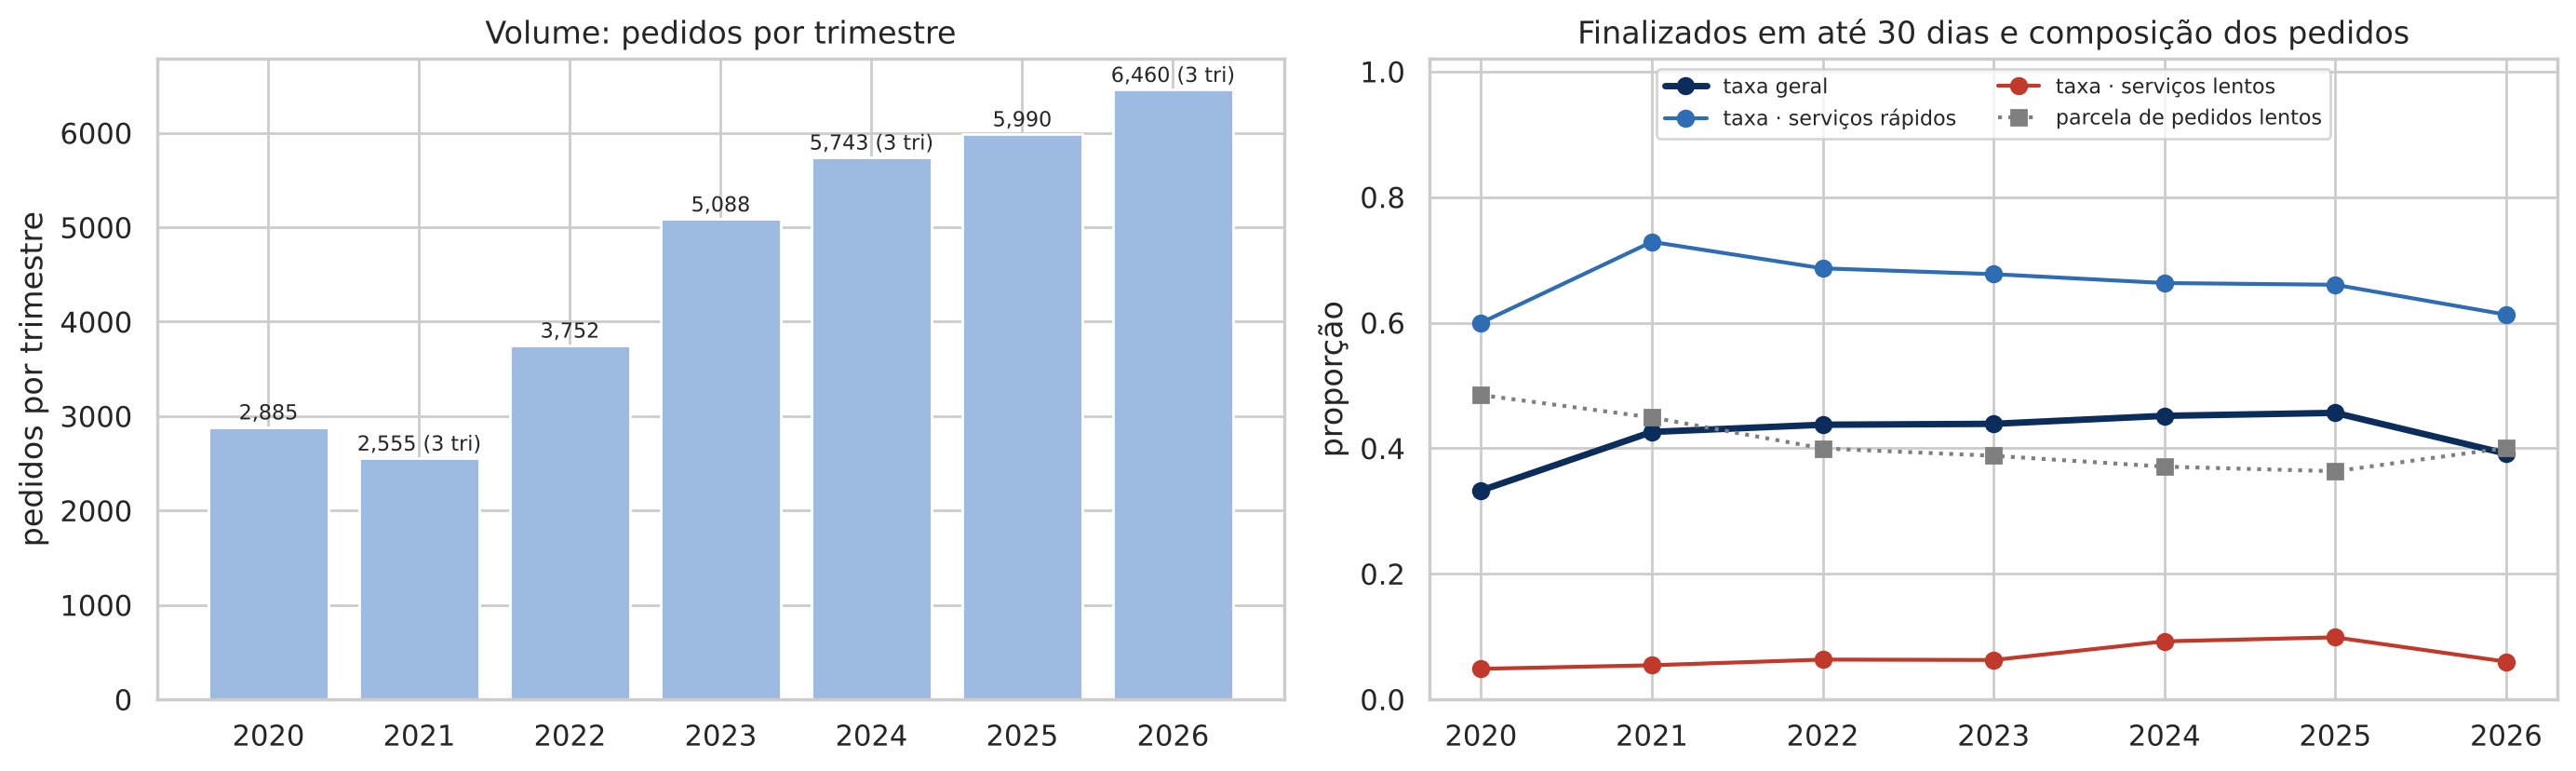

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
anos = por_ano.index.astype(str)
axes[0].bar(anos, por_ano.pedidos_por_trimestre, color="#9dbbe0")
for i, (v, t) in enumerate(zip(por_ano.pedidos_por_trimestre, por_ano.trimestres_na_base)):
    axes[0].text(i, v + 80, f"{v:,.0f}" + ("" if t == 4 else f" ({t} tri)"), ha="center", fontsize=8)
axes[0].set(title="Volume: pedidos por trimestre", ylabel="pedidos por trimestre")
axes[1].plot(anos, por_ano.taxa_geral, "-o", color="#0b2d5b", lw=2.5, label="taxa geral")
axes[1].plot(anos, por_ano.taxa_rapidos, "-o", color="#2e6db4", label="taxa · serviços rápidos")
axes[1].plot(anos, por_ano.taxa_lentos, "-o", color="#c0392b", label="taxa · serviços lentos")
axes[1].plot(anos, por_ano.parcela_lentos, ":s", color="#7f7f7f", label="parcela de pedidos lentos")
axes[1].set(ylim=(0, 1.02), title="Finalizados em até 30 dias e composição dos pedidos", ylabel="proporção")
axes[1].legend(fontsize=8, loc="upper center", ncol=2)
plt.tight_layout(); plt.savefig(FIG / "02_volume_e_taxa_por_ano.png", dpi=130); plt.show()

**Como ler:**
- **Esquerda:** quantos pedidos entram por trimestre em cada ano. Usamos a média por trimestre porque
  2021, 2024 e 2026 têm só 3 trimestres na base.
- **Direita:** a fração finalizada em até 30 dias. A linha grossa é o total; a azul e a vermelha separam
  os serviços rápidos e os lentos (obstáculo, calçada particular, guia irregular); a pontilhada cinza
  mostra quanto dos pedidos é do tipo lento.

**O que mostra:**
- **O volume cresceu:** de cerca de 2.900 pedidos por trimestre em 2020 para cerca de 6.000 em 2025 e 6.500 em 2026.
- **A taxa de resposta em 30 dias também subiu:** 33% em 2020 e 46% em 2025.
- **Mas a Prefeitura não ficou mais rápida no mesmo tipo de pedido.** Os serviços rápidos ficaram entre
  60% e 73% o período todo, e os lentos entre 5% e 10%. O que mudou foi a **composição**: os pedidos lentos
  caíram de 48% para 36% do total, e com menos deles na mistura a média geral sobe.
- **2026 caiu para 39%**, com queda nos dois grupos. O ano ainda está incompleto (jan. a set.), então
  ainda não dá para dizer se é tendência.

**Por que isso importa para o modelo:**
- a taxa muda com o tempo, então a divisão treino/teste precisa respeitar as datas (seção 4);
- o modelo precisa saber o tipo de serviço, senão confunde mudança de composição com mudança de desempenho.

## 4. Divisão treino/teste

- **Treino:** pedidos abertos de 2020 a 2024.
- **Teste:** pedidos abertos de jan/2025 a set/2026, nunca vistos no treino nem na validação cruzada.

**Em palavras simples:** o modelo aprende com o passado e é cobrado no período seguinte, como se
estivesse sendo usado de verdade no AJA. Sortear pedidos ao acaso misturaria 2026 no treino e deixaria a
nota artificialmente alta.

In [10]:
treino = df.data_abertura < "2025-01-01"
X_tr, y_tr = X[treino], y[treino]
X_te, y_te = X[~treino], y[~treino]
print(f"treino: {len(X_tr):,} pedidos ({df[treino].data_abertura.min():%m/%Y}–{df[treino].data_abertura.max():%m/%Y}) | positivos {y_tr.mean():.1%}")
print(f"teste:  {len(X_te):,} pedidos ({df[~treino].data_abertura.min():%m/%Y}–{df[~treino].data_abertura.max():%m/%Y}) | positivos {y_te.mean():.1%}")

treino: 71,794 pedidos (01/2020–12/2024) | positivos 42.3%
teste:  43,339 pedidos (01/2025–09/2026) | positivos 42.7%


### Baseline

A régua: para cada pedido, prever a taxa histórica (calculada só no treino) do seu tipo de serviço.
Ex.: se 7% dos pedidos de obstáculo na calçada saíram em até 30 dias no passado, a chance prevista para
qualquer novo pedido desse tipo é 7%. Se o XGBoost não superar isso, não vale a complexidade.

**Métricas usadas** (todas vão de 0 a 1; quanto maior, melhor):

| Métrica | Em palavras simples |
|---|---|
| ROC-AUC | Sorteando um pedido rápido e um lento, é a chance de o modelo dar nota maior ao rápido. 0,5 é chute; 1 é perfeito. Não depende do ponto de corte. |
| Acurácia | Fração de acertos no total. |
| Acurácia balanceada | Média dos acertos em cada classe; não se deixa enganar se uma classe for maior. |
| Precisão | Dos pedidos que o modelo disse “sai em 30 dias”, quantos realmente saíram. |
| Recall | Dos pedidos que realmente saíram em 30 dias, quantos o modelo encontrou. |
| F1 | Equilíbrio entre precisão e recall. |

Para transformar a chance em “sim/não”, usamos o ponto de corte (limiar) de 0,5.

In [11]:
taxa_servico = df[treino].groupby("servico").y.mean()
p_base_tr = df[treino].servico.map(taxa_servico)
p_base_te = df[~treino].servico.map(taxa_servico).fillna(y_tr.mean())

def metricas(y_true, prob, limiar=0.5):
    pred = (prob >= limiar).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, prob),
        "Acurácia": accuracy_score(y_true, pred),
        "Acurácia balanceada": balanced_accuracy_score(y_true, pred),
        "Precisão": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred),
        "F1": f1_score(y_true, pred),
    }

base = pd.DataFrame({"Treino": metricas(y_tr, p_base_tr), "Teste": metricas(y_te, p_base_te)})
base.style.format("{:.3f}")

,Treino,Teste
ROC-AUC,0.827,0.794
Acurácia,0.778,0.746
Acurácia balanceada,0.799,0.769
Precisão,0.670,0.640
Recall,0.937,0.928
F1,0.781,0.758


O baseline já é forte (AUC 0,79 no teste), o que confirma o que a exploração mostrou: o tipo de serviço
explica boa parte do tempo de resposta.

## 5. Modelo e treino com diferentes hiperparâmetros

**Por que XGBoost:**
- os dados são uma tabela com categorias (serviço, canal, região) e números; árvores de decisão em
  *boosting* são o método mais forte para esse formato;
- captura combinações sem precisarmos programá-las (ex.: o mesmo serviço demora mais em certas regiões);
- tem hiperparâmetros claros para controlar a complexidade, o que permite estudar overfitting;
- não exige normalizar as variáveis.

LSTM serve para séries temporais (não é o caso), KMeans não usa rótulo (não responde “sim/não”) e MLP
costuma perder para árvores em tabelas desse tamanho.

**Busca:** 3 hiperparâmetros, 4 × 3 × 2 = **24 combinações**, avaliadas com **validação cruzada temporal
(4 dobras) somente no treino**. Em cada dobra o modelo treina com meses mais antigos e é avaliado nos
meses seguintes; a nota de cada combinação é a média das 4 dobras. A métrica de escolha é ROC-AUC.

| Hiperparâmetro | Valores | Em palavras simples |
|---|---|---|
| `max_depth` | 3, 5, 8, 12 | quantas perguntas seguidas cada árvore pode fazer (mais = mais detalhista) |
| `learning_rate` | 0,03; 0,1; 0,3 | o tamanho do passo de cada árvore ao corrigir as anteriores (maior = aprende mais rápido, e decora mais fácil) |
| `n_estimators` | 150, 400 | quantas árvores o modelo soma |

In [12]:
grade = {
    "max_depth": [3, 5, 8, 12],
    "learning_rate": [0.03, 0.1, 0.3],
    "n_estimators": [150, 400],
}
xgb = XGBClassifier(
    subsample=0.9, colsample_bytree=0.9, eval_metric="logloss",
    tree_method="hist", n_jobs=-1, random_state=SEED,
)
busca = GridSearchCV(
    xgb, grade, scoring="roc_auc", cv=TimeSeriesSplit(n_splits=4),
    return_train_score=True, n_jobs=1, verbose=0,
)
busca.fit(X_tr, y_tr)  # X_tr está ordenado por data de abertura
print("melhor combinação:", busca.best_params_, f"| AUC validação = {busca.best_score_:.3f}")

melhor combinação: {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 400} | AUC validação = 0.841


In [13]:
res = pd.DataFrame(busca.cv_results_)
tabela = (
    res[["param_max_depth", "param_learning_rate", "param_n_estimators",
         "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score"]]
    .rename(columns={
        "param_max_depth": "max_depth", "param_learning_rate": "learning_rate",
        "param_n_estimators": "n_estimators", "mean_train_score": "AUC treino (CV)",
        "mean_test_score": "AUC validação (CV)", "std_test_score": "desvio validação",
        "rank_test_score": "posição",
    })
    .assign(**{"gap treino−validação": lambda t: t["AUC treino (CV)"] - t["AUC validação (CV)"]})
    .sort_values("posição")
    .reset_index(drop=True)
)
tabela.style.format({c: "{:.3f}" for c in tabela.columns if "AUC" in c or "gap" in c or "desvio" in c}).background_gradient(subset=["AUC validação (CV)"], cmap="Greens")

,max_depth,learning_rate,n_estimators,AUC treino (CV),AUC validação (CV),desvio validação,posição,gap treino−validação
0,5,0.030000,400,0.913,0.841,0.015,1,0.072
1,3,0.100000,400,0.908,0.840,0.014,2,0.068
2,5,0.100000,150,0.918,0.840,0.016,3,0.078
3,8,0.030000,150,0.920,0.840,0.015,4,0.081
4,5,0.030000,150,0.895,0.839,0.015,5,0.055
5,8,0.030000,400,0.951,0.839,0.015,6,0.113
6,3,0.300000,150,0.909,0.838,0.015,7,0.071
7,3,0.100000,150,0.894,0.838,0.015,8,0.056
8,3,0.030000,400,0.891,0.838,0.015,9,0.053
9,5,0.100000,400,0.943,0.838,0.015,10,0.105


**Como ler a tabela:**
- cada linha é uma combinação testada, da melhor para a pior pela AUC de validação;
- **AUC treino** é a nota nos meses em que o modelo aprendeu, e **AUC validação** a nota nos meses
  seguintes, que ele não viu;
- o **gap** é a diferença entre as duas: quanto maior, mais o modelo decorou;
- o **desvio** mostra quanto a nota variou entre as 4 dobras.

As 10 primeiras ficam muito próximas (0,838 a 0,841, diferenças menores que o desvio de cerca de 0,015).
Entre elas, as de menor gap são as mais confiáveis.

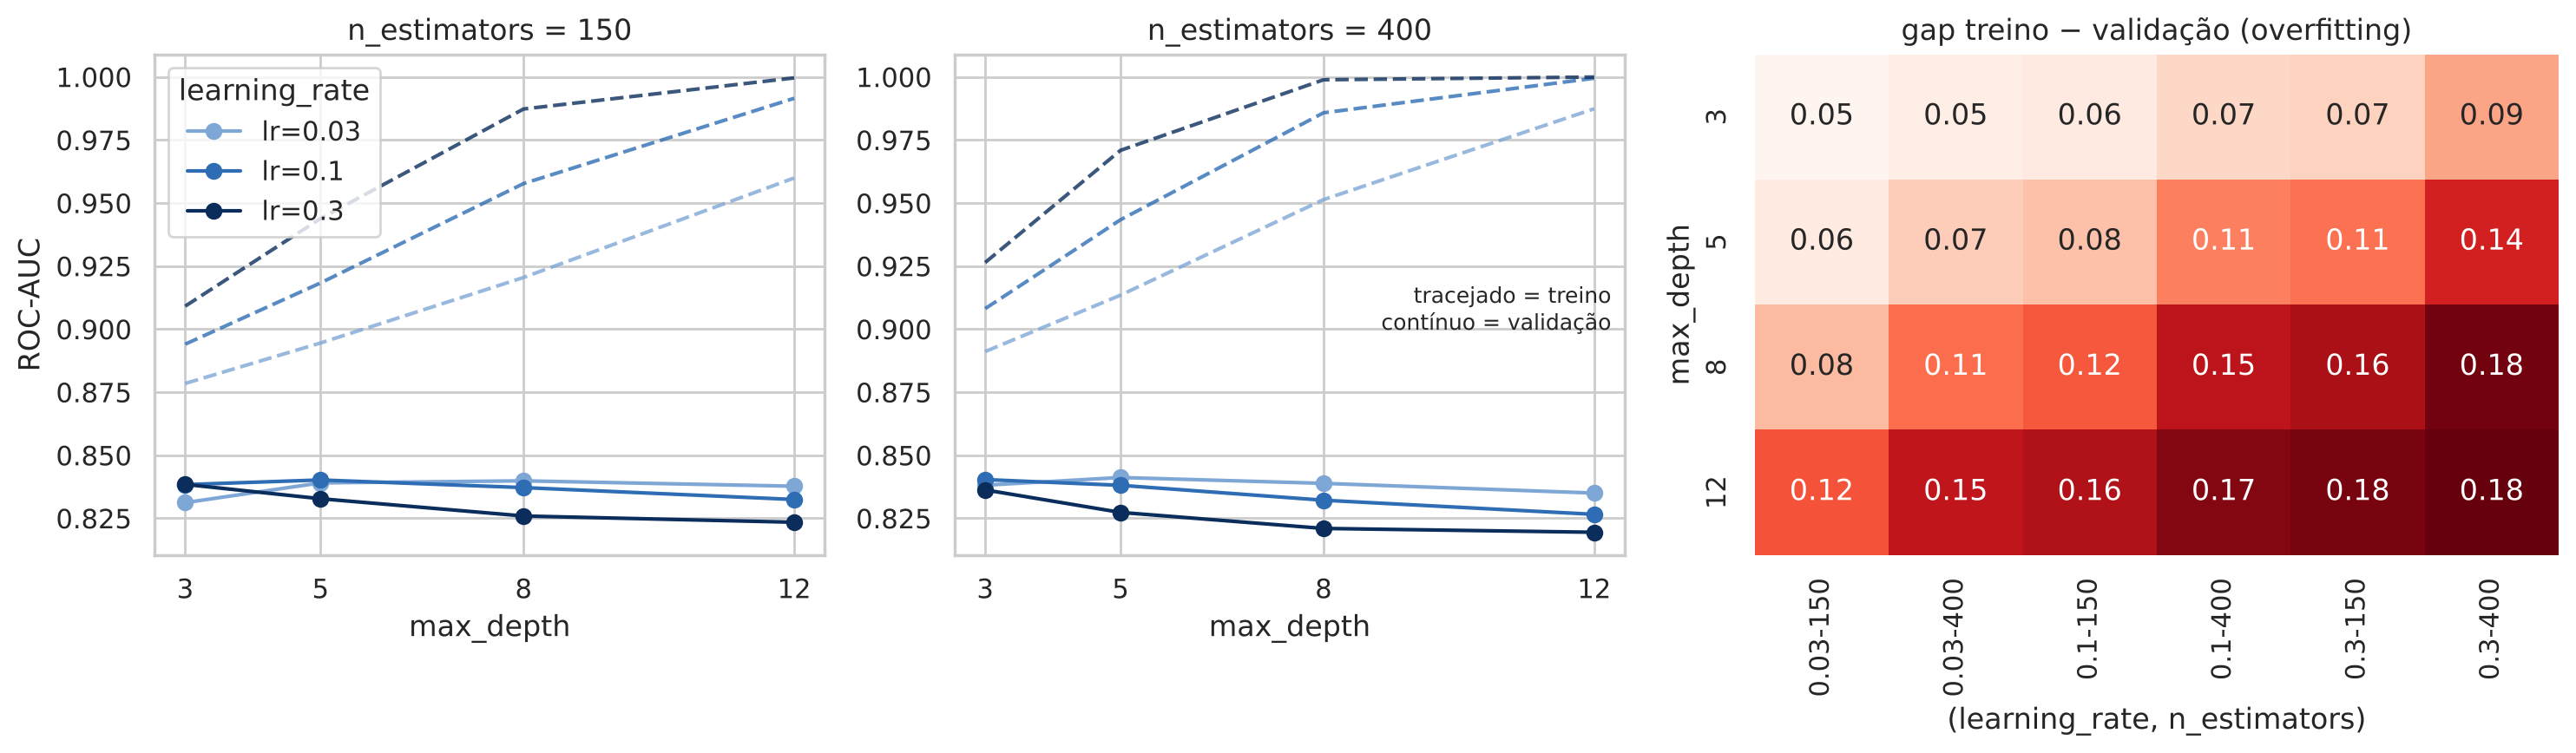

In [14]:
fig = plt.figure(figsize=(15, 4.5))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.2])
ax1 = fig.add_subplot(gs[0]); ax2 = fig.add_subplot(gs[1], sharey=ax1); ax3 = fig.add_subplot(gs[2])
for ax, n in zip([ax1, ax2], [150, 400]):
    for lr, cor in zip([0.03, 0.1, 0.3], ["#7fa7d6", "#2e6db4", "#0b2d5b"]):
        t = tabela[(tabela.n_estimators == n) & (tabela.learning_rate == lr)].sort_values("max_depth")
        ax.plot(t.max_depth, t["AUC treino (CV)"], "--", color=cor, alpha=.8)
        ax.plot(t.max_depth, t["AUC validação (CV)"], "-o", color=cor, label=f"lr={lr}")
    ax.set(title=f"n_estimators = {n}", xlabel="max_depth", xticks=[3, 5, 8, 12])
ax1.set_ylabel("ROC-AUC")
ax1.legend(title="learning_rate", loc="upper left")
ax2.text(0.98, 0.45, "tracejado = treino" + chr(10) + "contínuo = validação", transform=ax2.transAxes, ha="right", fontsize=9)
piv = tabela.pivot_table(index="max_depth", columns=["learning_rate", "n_estimators"], values="gap treino−validação")
sns.heatmap(piv, annot=True, fmt=".2f", cmap="Reds", ax=ax3, cbar=False)
ax3.set(title="gap treino − validação (overfitting)", xlabel="(learning_rate, n_estimators)", ylabel="max_depth")
plt.tight_layout(); plt.savefig(FIG / "03_curvas_hiperparametros.png", dpi=130); plt.show()

**Como ler:**
- **Linhas (esquerda e centro):** o eixo horizontal é a profundidade das árvores. As tracejadas mostram
  a nota no treino e as contínuas a nota na validação; cada cor é uma taxa de aprendizado.
- **Mapa de calor (direita):** cada quadrado é o gap de uma combinação. Quanto mais vermelho, maior o
  overfitting.

**O que mostra:**
- as linhas tracejadas sobem até quase 1 conforme as árvores ficam mais profundas e a taxa de
  aprendizado aumenta: o modelo passa a acertar quase tudo o que já viu;
- as contínuas ficam paradas em torno de 0,84 e depois **descem**: o que ele aprende a mais não serve
  para meses novos. Isso é overfitting;
- o mapa de calor resume o efeito: o gap vai de 0,05 (árvores rasas, passo pequeno) a 0,18 (árvores
  profundas, passo grande).

**Escolha:** `max_depth = 5`, `learning_rate = 0,03`, `n_estimators = 400`. São árvores de tamanho médio,
passo pequeno e muitas árvores, ou seja, o modelo aprende devagar e de forma estável. Teve a maior AUC de
validação, com gap moderado (0,07).

## 6. Resultados em treino e teste

O melhor modelo da busca é retreinado em todo o treino (o `GridSearchCV` faz isso automaticamente) e
avaliado uma única vez no teste. Para mostrar o overfitting na prática, comparamos também com a
combinação mais complexa da grade.

In [15]:
melhor = busca.best_estimator_
complexo = XGBClassifier(**{**xgb.get_params(), "max_depth": 12, "learning_rate": 0.3, "n_estimators": 400}).fit(X_tr, y_tr)

linhas = {}
for nome, prob_tr, prob_te in [
    ("Baseline (taxa por serviço)", p_base_tr, p_base_te),
    ("XGBoost escolhido", melhor.predict_proba(X_tr)[:, 1], melhor.predict_proba(X_te)[:, 1]),
    ("XGBoost mais complexo", complexo.predict_proba(X_tr)[:, 1], complexo.predict_proba(X_te)[:, 1]),
]:
    for conj, yt, p in [("Treino", y_tr, prob_tr), ("Teste", y_te, prob_te)]:
        linhas[(nome, conj)] = metricas(yt, p)
comparacao = pd.DataFrame(linhas).T
comparacao.style.format("{:.3f}")

**O que mostra a tabela:**
- **XGBoost escolhido × baseline:**
  - no teste, a AUC sobe de 0,794 para 0,831: o modelo ordena melhor os pedidos por chance de resposta;
  - a precisão também melhora (0,640 → 0,664): quando ele diz “sai em 30 dias”, acerta mais vezes;
  - com o limiar de 0,5, porém, a acurácia é parecida (0,746 → 0,751) e o F1 fica um pouco abaixo
    (0,758 → 0,743). O baseline diz “sim” com mais frequência e por isso encontra mais positivos
    (recall 0,928);
  - o ganho do modelo está em **ordenar e graduar a chance**, que é o que o AJA usa.
- **XGBoost mais complexo:** acerta praticamente 100% no treino e é o pior no teste (AUC 0,801, abaixo até
  do baseline). É o overfitting da busca confirmado em dados novos.

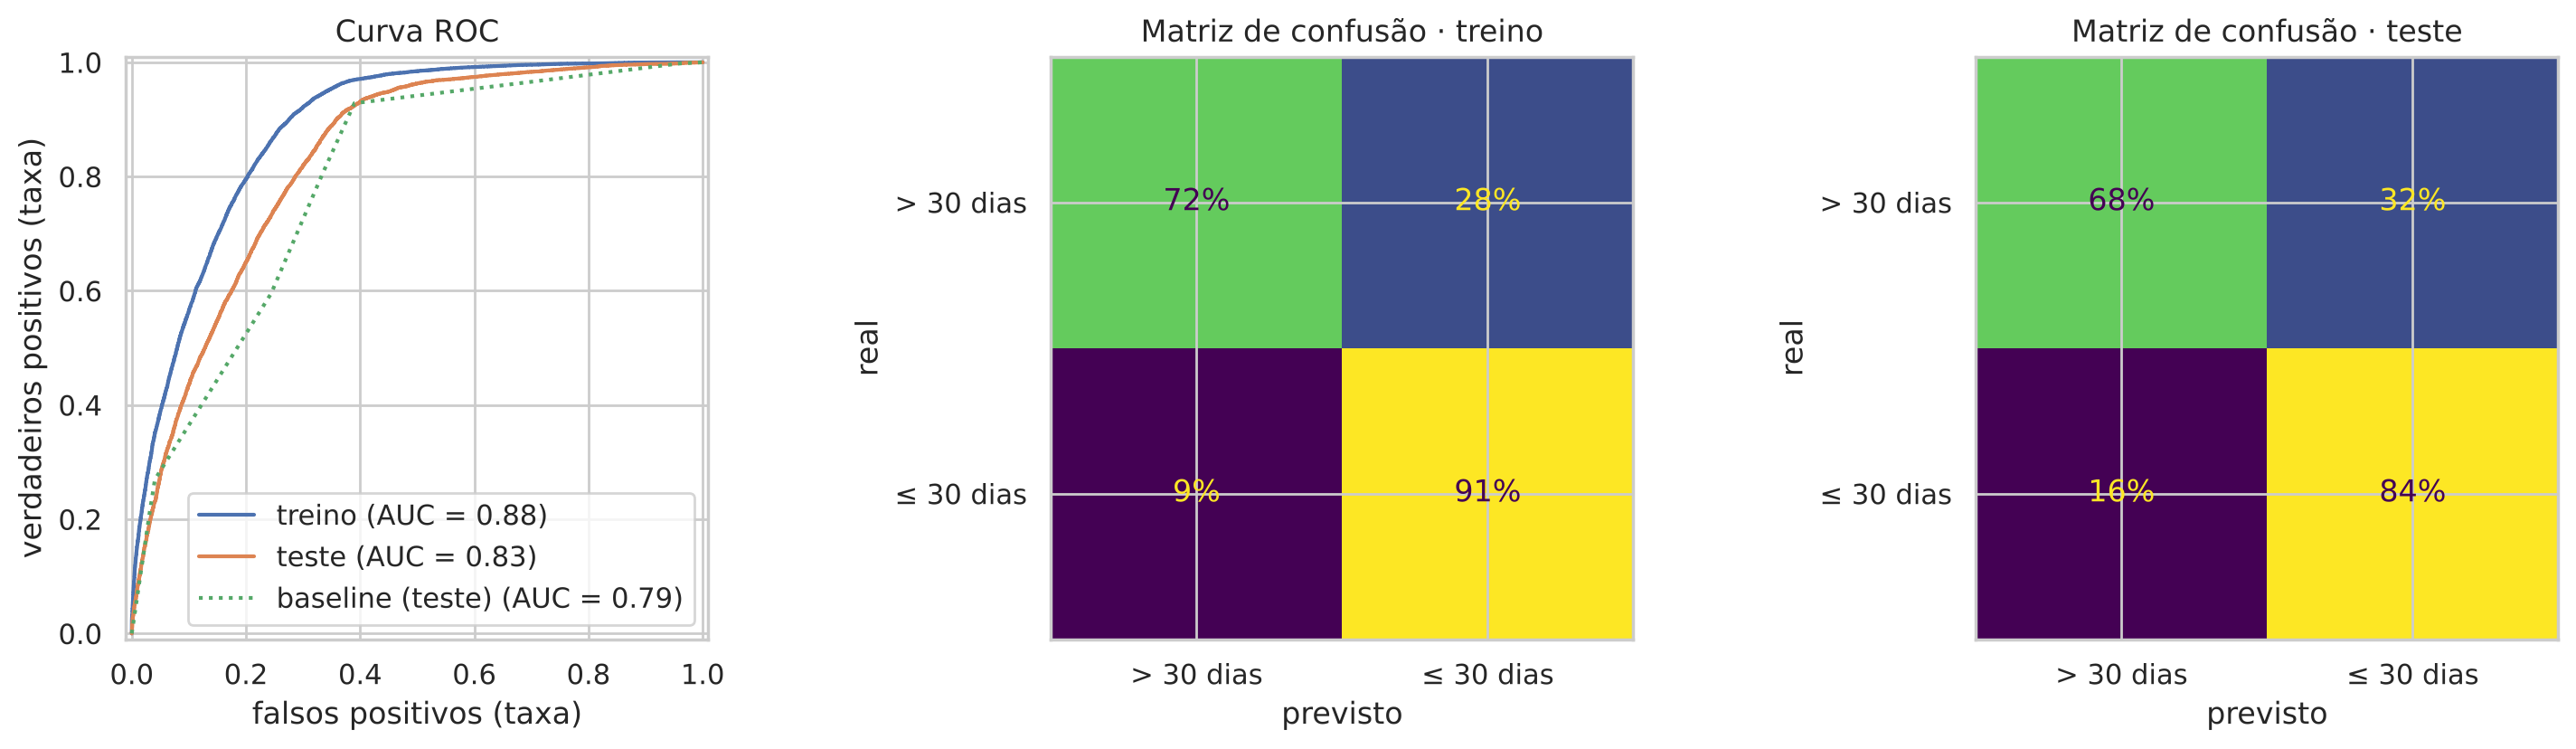

In [16]:
prob_te = melhor.predict_proba(X_te)[:, 1]
prob_tr = melhor.predict_proba(X_tr)[:, 1]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
RocCurveDisplay.from_predictions(y_tr, prob_tr, name="treino", ax=axes[0])
RocCurveDisplay.from_predictions(y_te, prob_te, name="teste", ax=axes[0])
RocCurveDisplay.from_predictions(y_te, p_base_te, name="baseline (teste)", ax=axes[0], curve_kwargs={"linestyle": ":"})
axes[0].set(title="Curva ROC", xlabel="falsos positivos (taxa)", ylabel="verdadeiros positivos (taxa)")
rot = ["> 30 dias", "≤ 30 dias"]
ConfusionMatrixDisplay.from_predictions(y_tr, (prob_tr >= .5).astype(int), ax=axes[1], normalize="true", values_format=".0%", display_labels=rot, colorbar=False)
axes[1].set(title="Matriz de confusão · treino", xlabel="previsto", ylabel="real")
ConfusionMatrixDisplay.from_predictions(y_te, (prob_te >= .5).astype(int), ax=axes[2], normalize="true", values_format=".0%", display_labels=rot, colorbar=False)
axes[2].set(title="Matriz de confusão · teste", xlabel="previsto", ylabel="real")
plt.tight_layout(); plt.savefig(FIG / "04_roc_confusao.png", dpi=130); plt.show()

**Como ler:**
- **Curva ROC:** mostra, para todos os pontos de corte possíveis, quantos pedidos rápidos o modelo
  encontra (eixo vertical) em troca de quantos alarmes falsos (eixo horizontal). Quanto mais a curva se
  aproxima do canto superior esquerdo, melhor. A área sob a curva é a AUC.
- **Matriz de confusão:** cada linha é o que aconteceu de verdade e soma 100%; cada coluna é o que o
  modelo previu. A diagonal são os acertos.

**O que mostra:**
- no teste, a curva do modelo fica acima da do baseline em quase toda a extensão;
- o modelo reconhece 84% dos pedidos que saem em 30 dias e 68% dos que demoram;
- os erros mais comuns são pedidos que o modelo achou que sairiam rápido e demoraram (32% dos lentos);
- do treino para o teste, as duas classes perdem alguns pontos, uma queda moderada.

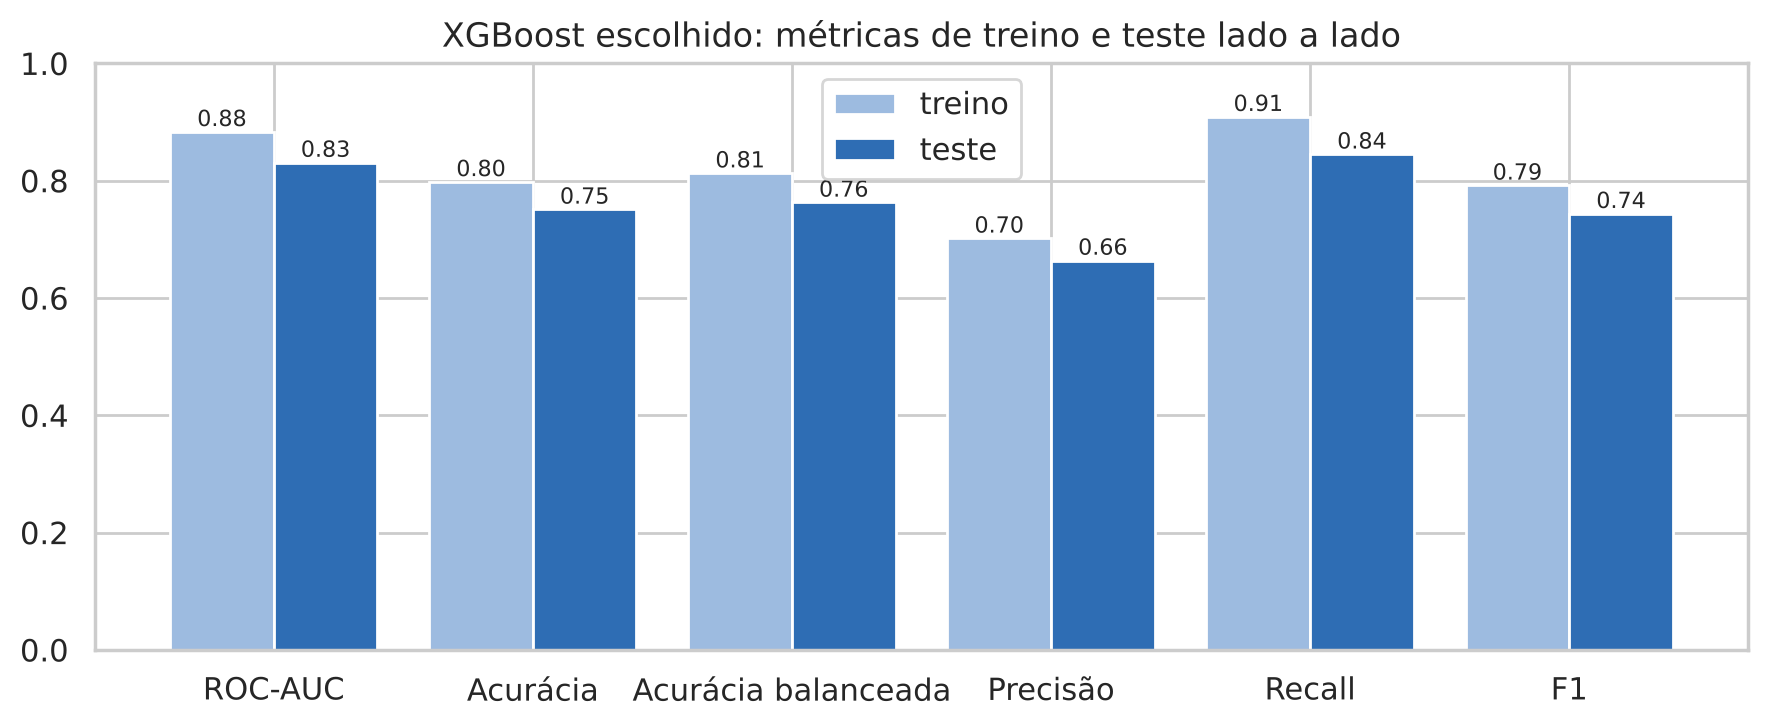

In [17]:
m = comparacao.loc[[("XGBoost escolhido", "Treino"), ("XGBoost escolhido", "Teste")]].droplevel(0)
x = np.arange(len(m.columns))
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(x - .2, m.loc["Treino"], .4, label="treino", color="#9dbbe0")
ax.bar(x + .2, m.loc["Teste"], .4, label="teste", color="#2e6db4")
for i in x:
    ax.text(i - .2, m.loc["Treino"].iloc[i] + .01, f"{m.loc['Treino'].iloc[i]:.2f}", ha="center", fontsize=8)
    ax.text(i + .2, m.loc["Teste"].iloc[i] + .01, f"{m.loc['Teste'].iloc[i]:.2f}", ha="center", fontsize=8)
ax.set(xticks=x, xticklabels=m.columns, ylim=(0, 1), title="XGBoost escolhido: métricas de treino e teste lado a lado")
ax.legend()
plt.tight_layout(); plt.savefig(FIG / "05_treino_vs_teste.png", dpi=130); plt.show()

**Como ler:** para cada métrica, a barra clara é o treino e a escura o teste. Barras parecidas indicam
que o modelo generaliza; uma barra de treino muito mais alta indicaria que ele decorou.

**O que mostra:** as quedas do treino para o teste são pequenas (de 0,04 a 0,06). A maior é no recall, que
cai de 0,91 para 0,84, coerente com a matriz de confusão.

### Overfitting

In [18]:
gap_melhor = comparacao.loc[("XGBoost escolhido", "Treino"), "ROC-AUC"] - comparacao.loc[("XGBoost escolhido", "Teste"), "ROC-AUC"]
gap_complexo = comparacao.loc[("XGBoost mais complexo", "Treino"), "ROC-AUC"] - comparacao.loc[("XGBoost mais complexo", "Teste"), "ROC-AUC"]
print(f"gap de AUC treino−teste | escolhido: {gap_melhor:.3f} | mais complexo: {gap_complexo:.3f}")

gap de AUC treino−teste | escolhido: 0.052 | mais complexo: 0.199


- **Modelo escolhido:** gap de 0,05 entre treino e teste. Generaliza para um período que nunca viu.
- **Modelo mais complexo:** gap de 0,20. Decorou o treino.
- **Nem toda queda é overfitting.** Parte dela vem da mudança ao longo do tempo vista na seção 3 (a taxa
  de 2026 caiu nos dois grupos de serviço). A validação temporal mede exatamente esse efeito, que um
  sorteio aleatório esconderia.

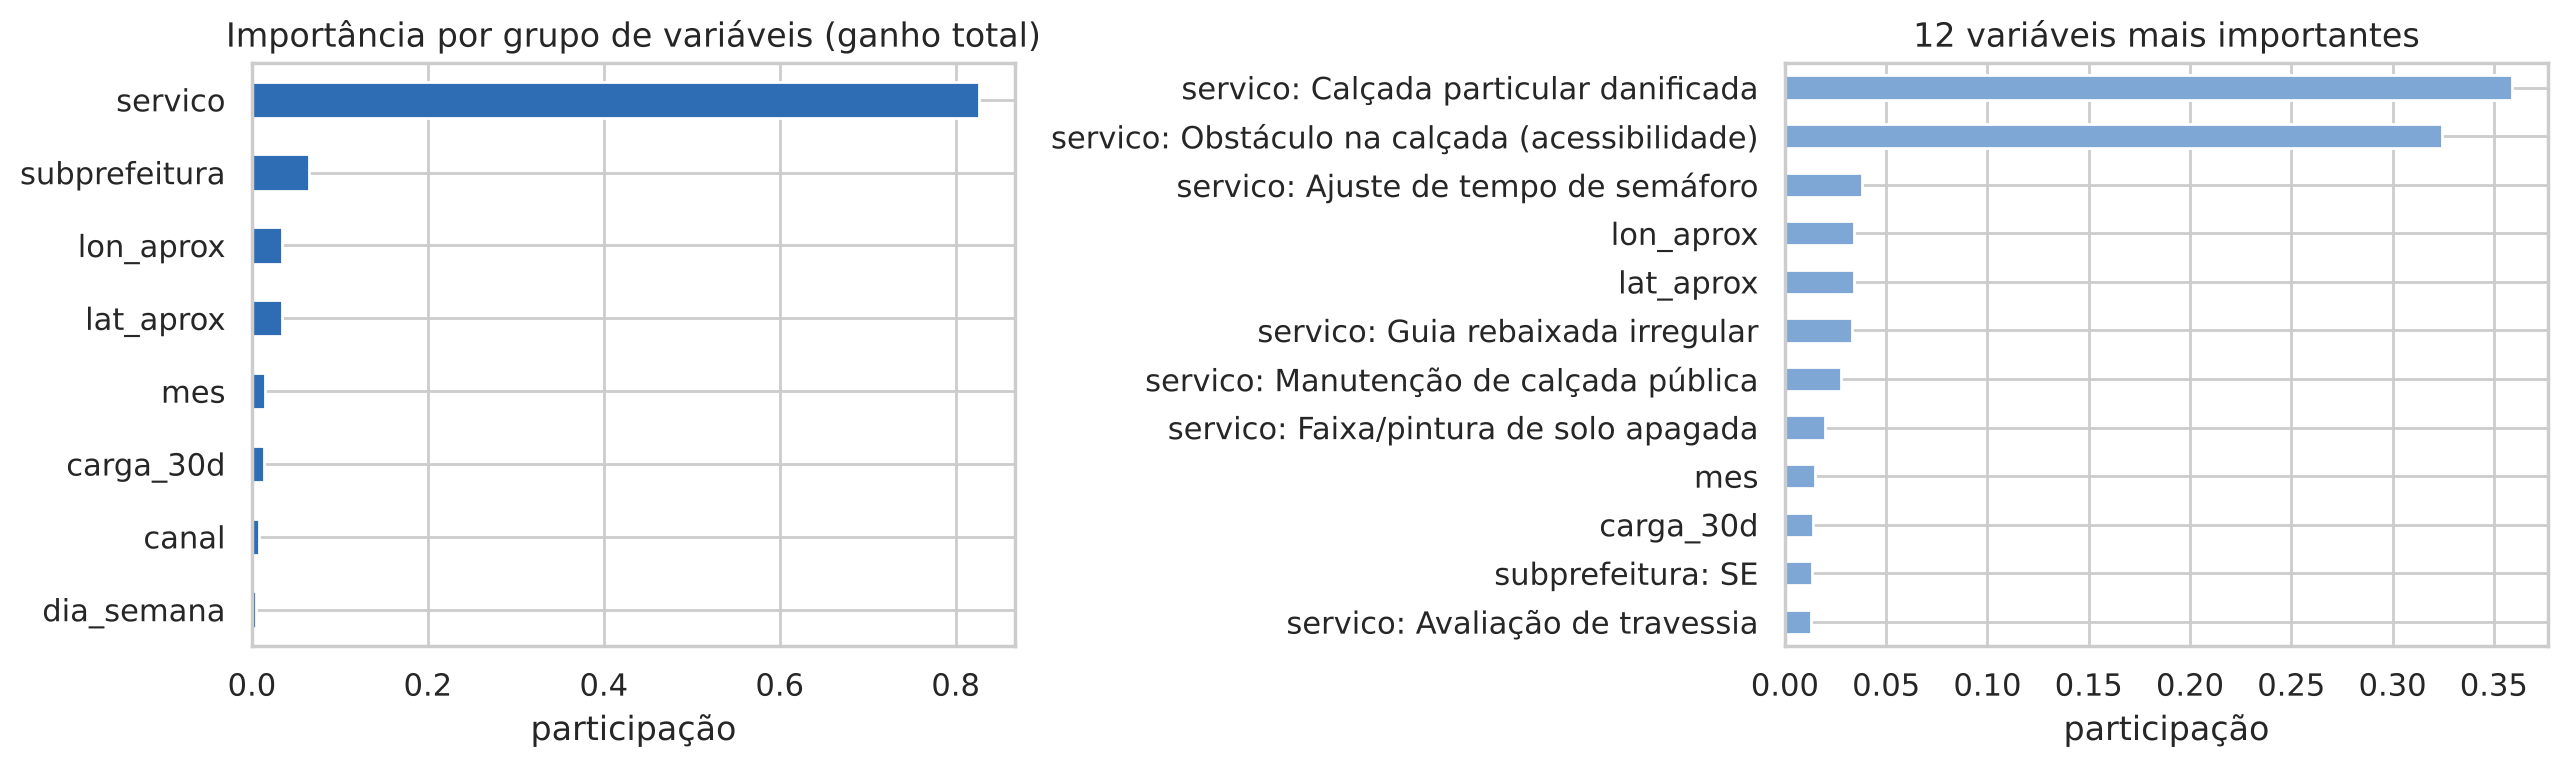

servico          0.826
subprefeitura    0.065
lon_aprox        0.034
lat_aprox        0.034
mes              0.015
carga_30d        0.014
canal            0.008
dia_semana       0.004


In [19]:
imp = pd.Series(melhor.get_booster().get_score(importance_type="total_gain")).sort_values(ascending=False)
rotulo = lambda c: next((f"{g}: " + NOME_CURTO.get(c[len(g) + 1:], c[len(g) + 1:]) for g in CATEGORICAS if c.startswith(g + "_")), c)
grupo = imp.groupby(lambda c: next((g for g in CATEGORICAS if c.startswith(g + "_")), c)).sum().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
(grupo / grupo.sum()).plot.barh(ax=axes[0], color="#2e6db4")
axes[0].set(title="Importância por grupo de variáveis (ganho total)", xlabel="participação")
(imp.head(12)[::-1] / imp.sum()).rename(rotulo).plot.barh(ax=axes[1], color="#7fa7d6")
axes[1].set(title="12 variáveis mais importantes", xlabel="participação")
plt.tight_layout(); plt.savefig(FIG / "06_importancia.png", dpi=130); plt.show()
print((grupo / grupo.sum()).sort_values(ascending=False).round(3).to_string())

**Como ler:** “ganho total” mede quanto cada variável ajudou o modelo a separar pedidos rápidos de
lentos, somando todas as árvores. À esquerda, as colunas do one-hot estão agrupadas por variável
original; à direita, as 12 colunas individuais que mais contribuíram.

**O que mostra:**
- o **tipo de serviço** responde por cerca de 80% do que o modelo aprendeu, e os dois serviços mais lentos
  (calçada particular e obstáculo na calçada) sozinhos somam quase 70%;
- **subprefeitura e localização** vêm em seguida: a mesma barreira demora mais em umas regiões do que em
  outras. É isso que faz o modelo superar o baseline;
- mês, carga da fila, canal e dia da semana pesam pouco.

## 7. Leitura para o cidadão

O que o modelo diz para quem usa o AJA no Parque Doroteia (Subprefeitura Cidade Ademar)? Abaixo, a chance
prevista de um pedido ser finalizado em até 30 dias, por tipo de barreira, comparada com o que aconteceu de
fato no período de teste nessa subprefeitura.

Como a amostra de uma única subprefeitura é pequena, a taxa real vem com um **intervalo de confiança de
95%** (intervalo de Wilson). Em palavras simples: é a faixa onde a taxa “verdadeira” provavelmente está;
quanto menos pedidos, mais larga a faixa.

In [20]:
def wilson(sucessos, n, z=1.96):
    p = sucessos / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margem = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margem, centro + margem

ademar = df[(~treino) & (df.subprefeitura == "CIDADE ADEMAR")].copy()
ademar["prob_30d"] = melhor.predict_proba(X.loc[ademar.index])[:, 1]
leitura = (
    ademar.groupby("servico")
    .agg(pedidos=("y", "size"), finalizados_30d=("y", "sum"), chance_prevista=("prob_30d", "mean"), taxa_real=("y", "mean"))
    .join(ademar[ademar.status == "Finalizada"].groupby("servico").dias_ate_finalizar.median().rename("mediana_dias_real"))
)
leitura[["ic95_min", "ic95_max"]] = [wilson(s, n) for s, n in zip(leitura.finalizados_30d, leitura.pedidos)]
leitura["previsao_dentro_do_ic"] = leitura.chance_prevista.between(leitura.ic95_min, leitura.ic95_max)
leitura = leitura.sort_values("chance_prevista")
leitura.index = leitura.index.map(NOME_CURTO)
print(f"Cidade Ademar, 2025–2026: {len(ademar):,} pedidos")
leitura.drop(columns="finalizados_30d").style.format(
    {c: "{:.0%}" for c in ["chance_prevista", "taxa_real", "ic95_min", "ic95_max"]} | {"mediana_dias_real": "{:.0f}"}
)

Cidade Ademar, 2025–2026: 918 pedidos


,pedidos,chance_prevista,taxa_real,mediana_dias_real,ic95_min,ic95_max,previsao_dentro_do_ic
servico,,,,,,,
Obstáculo na calçada (acessibilidade),198,2%,3%,98,1%,6%,True
Calçada particular danificada,119,5%,3%,77,1%,8%,True
Guia rebaixada irregular,6,8%,17%,5,3%,56%,True
Faixa/pintura de solo apagada,80,60%,60%,12,49%,70%,True
Avaliação de travessia,70,60%,34%,42,24%,46%,False
Manutenção de calçada pública,323,70%,83%,4,79%,87%,False
Rebaixamento de guia p/ travessia,31,72%,55%,7,38%,71%,False
Ajuste de tempo de semáforo,91,87%,96%,12,89%,98%,False


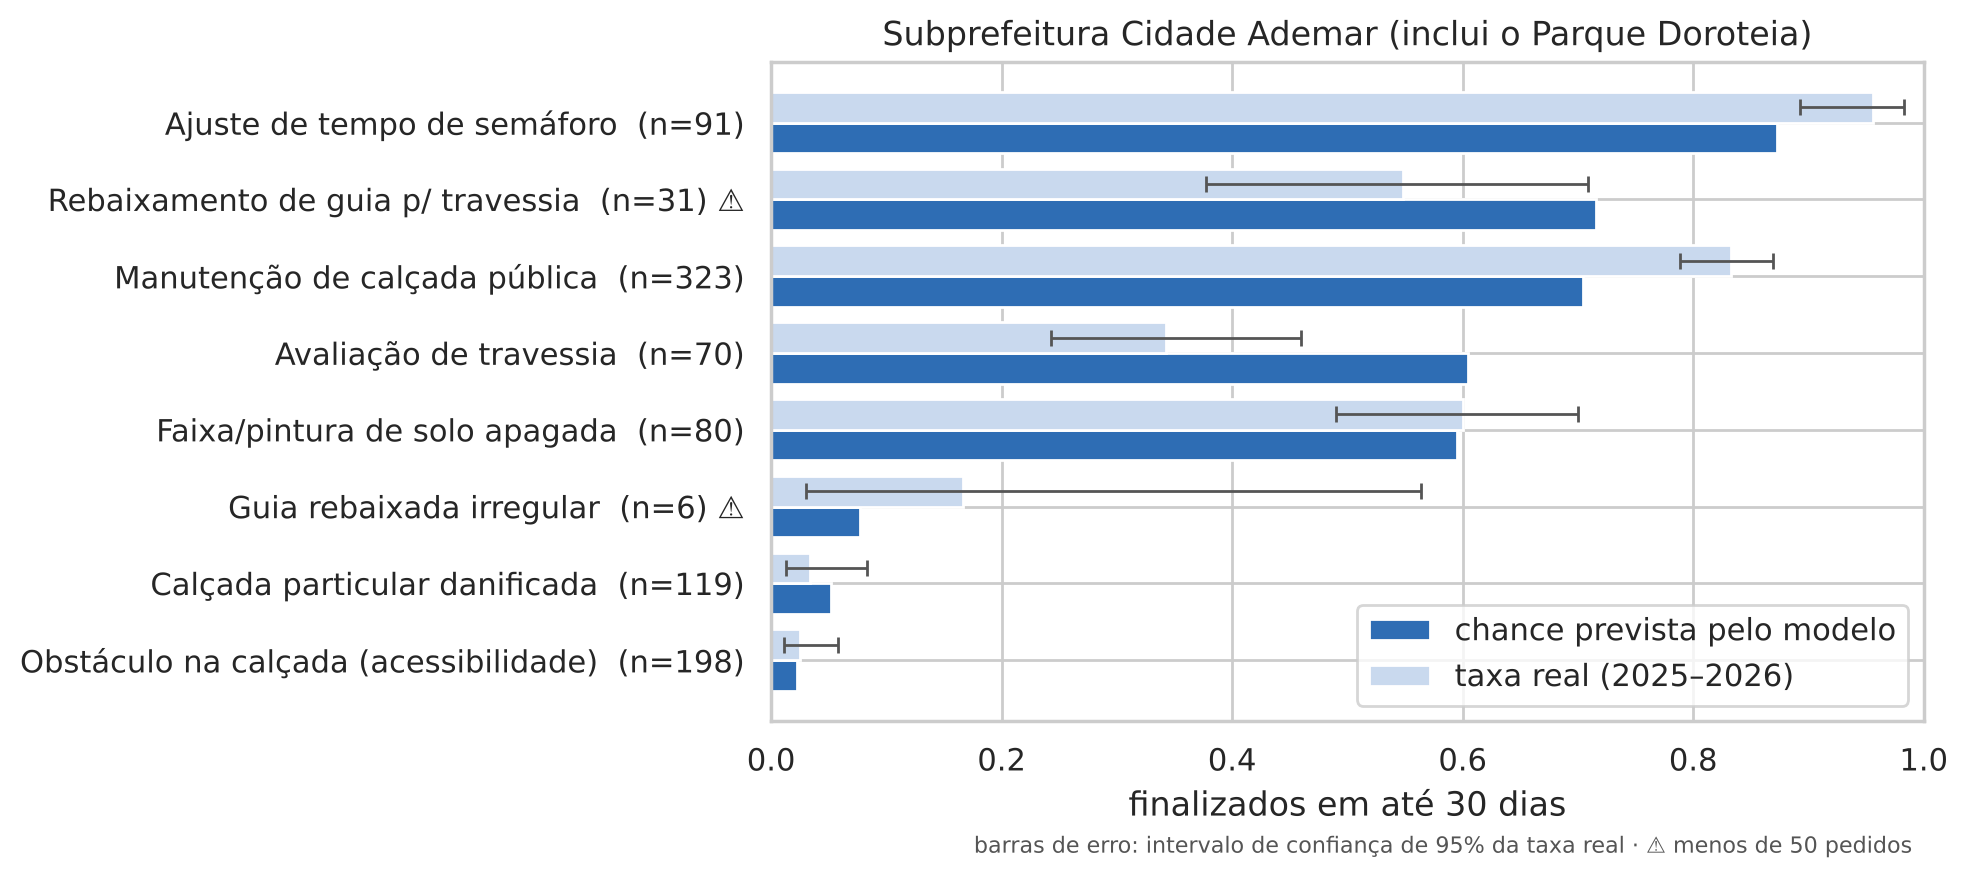

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.6))
pos = np.arange(len(leitura))
ax.barh(pos - .2, leitura.chance_prevista, .4, label="chance prevista pelo modelo", color="#2e6db4")
ax.barh(pos + .2, leitura.taxa_real, .4, label="taxa real (2025–2026)", color="#c9d9ee",
        xerr=[leitura.taxa_real - leitura.ic95_min, leitura.ic95_max - leitura.taxa_real],
        error_kw={"ecolor": "#555", "capsize": 3, "lw": 1})
rotulos = [f"{s}  (n={n})" + (" ⚠" if n < 50 else "") for s, n in zip(leitura.index, leitura.pedidos)]
ax.set(yticks=pos, yticklabels=rotulos, xlim=(0, 1),
       xlabel="finalizados em até 30 dias", title="Subprefeitura Cidade Ademar (inclui o Parque Doroteia)")
ax.legend(loc="lower right")
ax.text(0.99, -0.2, "barras de erro: intervalo de confiança de 95% da taxa real · ⚠ menos de 50 pedidos",
        transform=ax.transAxes, ha="right", fontsize=8, color="#555")
plt.tight_layout(); plt.savefig(FIG / "07_cidade_ademar.png", dpi=130); plt.show()

**Como ler:** para cada tipo de barreira, a barra escura é a chance média que o modelo previu e a barra
clara é o que aconteceu de verdade. O traço preto sobre a barra clara é o intervalo de confiança: se a
barra escura cai dentro dele, a previsão é compatível com a realidade. Ao lado do nome está o número de
pedidos (n); ⚠ marca amostras pequenas.

**O que mostra:**
- **Onde há dados suficientes, o modelo acerta bem:**
  - obstáculo na calçada: n=198, previsto 2%, real 3%;
  - calçada particular: n=119, previsto 5%, real 3%;
  - faixa apagada: n=80, previsto 60%, real 60%.
- **Em dois serviços rápidos, o modelo prevê um pouco abaixo do real:** ajuste de semáforo (n=91, 87%
  contra 96%) e manutenção de calçada (n=323, 70% contra 83%). As previsões ficam fora do intervalo, então a
  diferença é real: a Cidade Ademar resolve esses pedidos mais rápido que a média da cidade.
- **Avaliação de travessia é o maior desvio:** previsto 60%, real 34% (n=70). A diferença fica fora do
  intervalo de confiança, então não é acaso. Na Cidade Ademar esse serviço demora mais que no resto da
  cidade, e o modelo ainda não capta isso.
- **Amostras pequenas não permitem conclusão:**
  - guia rebaixada irregular tem só 6 pedidos, e o intervalo vai de 3% a 56%: qualquer previsão nessa
    faixa é compatível com o que aconteceu;
  - rebaixamento de guia (n=31, previsto 72%, real 55%) fica no limite do intervalo (38% a 71%); com tão
    poucos casos, não dá para afirmar que o modelo errou.
- **Por que há tanta variação:** uma única subprefeitura gera poucos pedidos por serviço em 21 meses, e
  pequenas mudanças (uma equipe a mais ou a menos, um mutirão) mexem muito na taxa. Por isso:
  - o modelo aprende com a cidade inteira e usa a região como ajuste;
  - o AJA deve mostrar a previsão junto com o número de casos que a sustentam.

## 8. Conclusões

**Sobre a escolha do algoritmo.** O XGBoost foi adequado: a base é tabular, o efeito do tipo de serviço
combina com o da região e a complexidade é controlável por hiperparâmetros. A busca mostrou que árvores
de tamanho médio com aprendizado lento generalizam melhor; árvores profundas decoram o treino.

**Sobre os resultados.**
- O modelo escolhido tem AUC de **0,831 no teste**, contra 0,794 do baseline, com gap pequeno em relação
  ao treino (0,05).
- O ganho sobre o baseline é moderado e vem principalmente da região e da localização. O tipo de serviço,
  sozinho, já explica a maior parte.
- Com limiar de 0,5, acurácia e F1 ficam próximos do baseline. A vantagem prática está na **chance
  graduada**, que permite priorizar.

**Sobre o problema.** As barreiras que mais afetam pessoas com deficiência visual (obstáculo na calçada,
calçada particular danificada) são justamente as mais lentas: mediana de 266 e 234 dias, e só 7% finalizadas
em até 30 dias. Manutenção de calçada pública leva 12 dias.

**O que isso agrega ao AJA.**
- **Expectativa realista:** ao registrar uma barreira, o cidadão vê quanto tempo pedidos parecidos
  costumam levar.
- **Acompanhamento ativo:** quando a chance é baixa, o tópico já nasce com lembretes, convite à comunidade
  para confirmar e reforçar evidências e inclusão no dossiê para a subprefeitura.
- **Tópicos fundamentados:** dados públicos como o SP156 se somam aos relatos da comunidade. Uma barreira
  com histórico de demora vira um tópico com evidências, em vez de uma reclamação isolada.

**Limites.**
- O modelo prevê quando o **protocolo é encerrado**, não se a barreira foi removida; por isso o AJA mantém
  a confirmação pela comunidade e a avaliação de antes e depois.
- Em recortes pequenos (uma subprefeitura, um serviço raro) a incerteza é alta.
- A previsão orienta o acompanhamento e nunca deve desestimular um registro: chance baixa é argumento
  para pressionar, não para desistir.

**Próximos passos:**
- prever o tempo em dias, e não só “até 30 dias” (análise de sobrevivência);
- incluir características do entorno do Censo 2022 (calçadas, rampas e obstáculos por quadra).